Подключение библиотек

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

Начальные данные:\
V = 100 л\
Cin = 0.5 кг/л\
q = 5 л/мин\
m(0) = 0\
Найти массу соли m(t) в баке и построить её график

In [43]:
t, V, Cin, q = sp.symbols('t V Cin q', positive=True)
m = sp.Function('m')

ДУ

In [46]:
ode_m = sp.Eq(sp.diff(m(t), t) + q/V *m(t), Cin*q)
sp.pprint(ode_m)

d          q⋅m(t)        
──(m(t)) + ────── = Cin⋅q
dt           V           


In [48]:
sol_m = sp.dsolve(ode_m, ics={m(0): 0})
sp.pprint(sol_m)

                      -q⋅t 
                      ─────
                        V  
m(t) = Cin⋅V - Cin⋅V⋅ℯ     


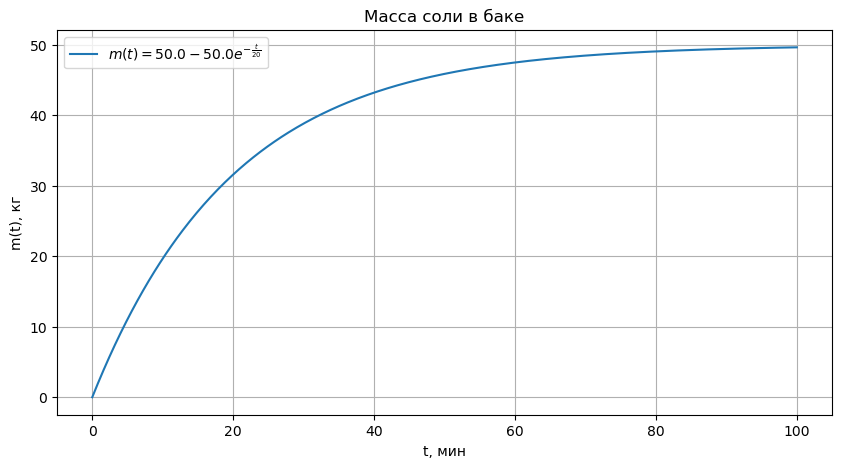

In [72]:
m_expr = sp.simplify(sol_m.rhs.subs({
    V: 100,
    Cin: 0.5,
    q: 5
}))
m_func = sp.lambdify(t, m_expr, 'numpy')
t_vals = np.linspace(0, 100, 500)
m_vals = m_func(t_vals)
plt.figure(figsize=(10, 6))
plt.plot(t_vals, m_vals, label=rf'$m(t)={sp.latex(m_expr)}$')
plt.xlabel('t, мин')
plt.ylabel('m(t), кг')
plt.title('Масса соли в баке')
plt.grid(True)
plt.legend()
plt.show()